# 02 — Traditional Machine Learning Baseline

## Fraud Detection using Graphs

**Dataset:** IBM AML — HI-Small

### Objectives
- Prepare transaction-level features
- Perform a chronological train/validation/test split
- Train a non-graph-based XGBoost classifier
- Evaluate minority-class detection performance
- Establish a baseline for comparison with graph-based methods

**Target:** Is Laundering (0 = normal, 1 = money laundering)


## Conclusion / Key Findings

This notebook establishes an XGBoost baseline for detecting money laundering in the IBM AML HI-Small dataset (approximately 5.08 million transactions).

### Main Results

- **Hyperparameter tuning:** Improved validation Average Precision (AP) from 0.0475 to **0.0667**.
- **Optimized classification threshold (0.037):** Achieved **11.02% precision, 20.89% recall, and 14.43% F1-score** on the validation set.
- **Test performance:** The tuned model achieved **AP = 0.1655, precision = 26.07%, recall = 27.09%, and F1 = 26.57%**.
- **Undersampling:** Slightly improved validation F1-score (14.43% to 14.77%), but reduced AP (0.0667 to 0.0637). Therefore, it did not provide a clear overall improvement.
- **Cost-sensitive threshold optimization:** Assuming a false negative costs 10 times more than a false positive, the original model achieved a minimum validation cost of **10,206** at threshold 0.061, compared with **10,225** for the undersampled model at threshold 0.746.

### Overall Conclusion

The tuned XGBoost model provides a useful non-graph baseline. However, detecting money laundering remains challenging because the dataset is highly imbalanced and many suspicious transactions are still missed.

**Next step:** Construct a transaction graph, extract graph-based features (e.g., in-degree, out-degree, transaction frequency), and evaluate whether these features improve fraud detection compared with the existing XGBoost baseline.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier
from sklearn.model_selection import ParameterSampler
from time import perf_counter


In [2]:
DATA_PATH = Path("../data/HI-Small_Trans.csv")

df = pd.read_csv(DATA_PATH)

df = df.rename(columns={
    "Account": "From Account",
    "Account.1": "To Account"
})

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    format="%Y/%m/%d %H:%M"
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5078345, 11)


,Timestamp,From Bank,From Account,To Bank,To Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [3]:
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

df["Log Amount Paid"] = np.log1p(
    df["Amount Paid"].clip(lower=0)
)

df["Log Amount Received"] = np.log1p(
    df["Amount Received"].clip(lower=0)
)

# Transaction-level features: no future observations or labels are used.
df["Amounts Equal"] = np.isclose(
    df["Amount Paid"], df["Amount Received"]
).astype("uint8")
df["Same Currency"] = (
    df["Payment Currency"] == df["Receiving Currency"]
).astype("uint8")
df["Same Bank"] = (df["From Bank"] == df["To Bank"]).astype("uint8")
df["Same Account"] = (
    (df["From Bank"] == df["To Bank"])
    & (df["From Account"] == df["To Account"])
).astype("uint8")


In [4]:
numeric_features = [
    "Amount Paid",
    "Amount Received",
    "Log Amount Paid",
    "Log Amount Received",
    "Hour",
    "DayOfWeek"
]

categorical_features = [
    "Payment Currency",
    "Receiving Currency",
    "Payment Format"
]

target = "Is Laundering"

baseline_numeric_features = numeric_features.copy()
extra_features = ["Amounts Equal", "Same Currency", "Same Bank", "Same Account"]
numeric_features += extra_features


In [5]:
# Place every transaction with the same timestamp in the same partition.
df = df.sort_values("Timestamp", kind="stable").reset_index(drop=True)
n = len(df)
train_cutoff = df.iloc[int(n * 0.60)]["Timestamp"]
test_cutoff = df.iloc[int(n * 0.80)]["Timestamp"]
train_df = df.loc[df["Timestamp"] < train_cutoff].copy()
val_df = df.loc[
    (df["Timestamp"] >= train_cutoff) & (df["Timestamp"] < test_cutoff)
].copy()
test_df = df.loc[df["Timestamp"] >= test_cutoff].copy()

assert train_df["Timestamp"].max() < val_df["Timestamp"].min()
assert val_df["Timestamp"].max() < test_df["Timestamp"].min()
for name, subset in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    assert subset[target].nunique() == 2, f"{name} must contain both classes"
    print(name, subset.shape, subset["Timestamp"].min(),
          subset["Timestamp"].max(), "Laundering:", subset[target].sum(),
          "Rate:", f"{subset[target].mean():.4%}")


Train (3046861, 19) 2022-09-01 00:00:00 2022-09-06 13:35:00 Laundering: 2297 Rate: 0.0754%
Validation (1015602, 19) 2022-09-06 13:36:00 2022-09-08 16:11:00 Laundering: 1082 Rate: 0.1065%
Test (1015882, 19) 2022-09-08 16:12:00 2022-09-18 16:18:00 Laundering: 1798 Rate: 0.1770%


In [6]:
X_train = pd.get_dummies(
    train_df[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=np.uint8
)

X_val = pd.get_dummies(
    val_df[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=np.uint8
)

X_test = pd.get_dummies(
    test_df[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=np.uint8
)

X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

baseline_columns = [c for c in X_train.columns if c not in extra_features]


Training features: (3046861, 47)
Validation features: (1015602, 47)
Test features: (1015882, 47)


In [7]:
dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_val)

print(classification_report(
    y_val,
    dummy_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1014520
           1       0.00      0.00      0.00      1082

    accuracy                           1.00   1015602
   macro avg       0.50      0.50      0.50   1015602
weighted avg       1.00      1.00      1.00   1015602



## Validation protocol

Compare the original features with the new transaction features before tuning.
Rank models with validation **average precision (AP)**; AP is not identical to
trapezoidal PR-AUC or XGBoost's `aucpr`. Select the decision threshold on validation
only. Repeated validation tuning can overfit this period; for larger searches use
additional chronological development folds. The test is evaluated only after all
choices are frozen. Notebook 01 explored labels across the full dataset, so this
holdout is not completely independent of exploratory feature design.

Account-history and graph features are deliberately reserved for a separate
experiment. Any such features must use strictly earlier transactions only.


In [9]:
negative = int((y_train == 0).sum())
positive = int((y_train == 1).sum())
scale_pos_weight = negative / positive
print("Training class ratio:", scale_pos_weight)

validation_results = []

def evaluate_validation(name, scores, threshold=0.5):
    pred = (scores >= threshold).astype("uint8")
    row = {
        "Model": name,
        "AP": average_precision_score(y_val, scores),
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "Alerts": int(pred.sum()),
    }
    validation_results.append(row)
    return row

# Unchanged original hyperparameters, evaluated with the corrected split.
original_params = dict(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight, tree_method="hist",
    eval_metric="aucpr", random_state=42, n_jobs=-1,
)
baseline_model = XGBClassifier(**original_params)
baseline_model.fit(X_train[baseline_columns], y_train,
                   eval_set=[(X_val[baseline_columns], y_val)], verbose=False)
baseline_scores = baseline_model.predict_proba(X_val[baseline_columns])[:, 1]
evaluate_validation("Original features", baseline_scores)

feature_model = XGBClassifier(**original_params)
feature_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
feature_scores = feature_model.predict_proba(X_val)[:, 1]
evaluate_validation("Extra features, original parameters", feature_scores)
pd.DataFrame(validation_results)


Training class ratio: 1325.4523291249457


,Model,AP,Threshold,Precision,Recall,F1,Alerts
0,Original features,0.047725,0.5,0.011387,0.838262,0.022469,79651
1,"Extra features, original parameters",0.047544,0.5,0.011510,0.841035,0.022709,79061


## Small randomized parameter search with early stopping

The values below are experiment candidates, not established optimal settings.
Ten trials plus the two comparisons above can take time on the full dataset.
Models are trained sequentially to avoid CPU oversubscription. Only the current
best tuned model is kept in memory. `n_estimators` is an upper bound; early
stopping monitors validation `aucpr`, while trial ranking uses sklearn AP.


In [10]:
N_TRIALS = 10
parameter_space = {
    "scale_pos_weight": [1.0, 30.0, 100.0, 300.0, scale_pos_weight],
    "max_depth": [3, 5, 7],
    "min_child_weight": [1, 10, 50],
    "reg_lambda": [1.0, 10.0],
}
search_results = []
best_search_model = None
best_search_ap = -np.inf
for trial, params in enumerate(
    ParameterSampler(parameter_space, n_iter=N_TRIALS, random_state=42), start=1
):
    started = perf_counter()
    candidate = XGBClassifier(
        n_estimators=2000, early_stopping_rounds=50,
        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", eval_metric="aucpr", random_state=42,
        n_jobs=-1, **params,
    )
    candidate.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    scores = candidate.predict_proba(X_val)[:, 1]
    ap = average_precision_score(y_val, scores)
    search_results.append({
        "Trial": trial, **params, "AP": ap,
        "Best trees": candidate.best_iteration + 1,
        "Seconds": perf_counter() - started,
    })
    print(f"Trial {trial}/{N_TRIALS}: AP={ap:.6f}, "
          f"trees={candidate.best_iteration + 1}, "
          f"seconds={search_results[-1]['Seconds']:.1f}", flush=True)
    if ap > best_search_ap:
        best_search_ap = ap
        best_search_model = candidate

search_table = pd.DataFrame(search_results).sort_values("AP", ascending=False)
display(search_table)
search_scores = best_search_model.predict_proba(X_val)[:, 1]
evaluate_validation("Tuned extra features", search_scores)
display(pd.DataFrame(validation_results).sort_values("AP", ascending=False))

# Keep the strongest validation AP, even if tuning/new features do not help.
choices = [
    ("Original features", baseline_model, baseline_columns, baseline_scores),
    ("Extra features, original parameters", feature_model,
     list(X_train.columns), feature_scores),
    ("Tuned extra features", best_search_model,
     list(X_train.columns), search_scores),
]
selected_name, model, selected_columns, val_scores = max(
    choices, key=lambda item: average_precision_score(y_val, item[3])
)
print("Selected model:", selected_name)


Trial 1/10: AP=0.065401, trees=262, seconds=55.1
Trial 2/10: AP=0.054058, trees=606, seconds=102.0
Trial 3/10: AP=0.046928, trees=298, seconds=59.2
Trial 4/10: AP=0.063164, trees=158, seconds=41.9
Trial 5/10: AP=0.063315, trees=386, seconds=68.9
Trial 6/10: AP=0.060024, trees=519, seconds=88.5
Trial 7/10: AP=0.046122, trees=142, seconds=33.2
Trial 8/10: AP=0.066664, trees=72, seconds=24.1
Trial 9/10: AP=0.062081, trees=386, seconds=68.1
Trial 10/10: AP=0.049144, trees=337, seconds=68.0


,Trial,scale_pos_weight,reg_lambda,min_child_weight,max_depth,AP,Best trees,Seconds
7,8,1.000000,10.0,1,7,0.066664,72,24.146010
0,1,1.000000,1.0,10,5,0.065401,262,55.065921
4,5,1.000000,1.0,1,3,0.063315,386,68.927930
3,4,1.000000,1.0,10,7,0.063164,158,41.874538
8,9,1.000000,1.0,10,3,0.062081,386,68.053214
5,6,30.000000,10.0,50,3,0.060024,519,88.527009
1,2,100.000000,1.0,50,3,0.054058,606,101.977638
9,10,1325.452329,1.0,10,5,0.049144,337,68.031546
2,3,1.000000,10.0,50,5,0.046928,298,59.175946
6,7,1325.452329,10.0,1,5,0.046122,142,33.185368


,Model,AP,Threshold,Precision,Recall,F1,Alerts
2,Tuned extra features,0.066664,0.5,0.000000,0.000000,0.000000,0
0,Original features,0.047725,0.5,0.011387,0.838262,0.022469,79651
1,"Extra features, original parameters",0.047544,0.5,0.011510,0.841035,0.022709,79061


Selected model: Tuned extra features


## Select the operating threshold on validation

F1 is a starting objective. An operational system may instead require a minimum
precision or a fixed daily review budget. Weighted model scores should not be
interpreted as calibrated laundering probabilities. The 1,000-alert report below
is for the entire partition, not per day.


Selected threshold: 0.03698771819472313


,Model,AP,Threshold,Precision,Recall,F1,Alerts
0,Original features,0.047725,0.500000,0.011387,0.838262,0.022469,79651
1,"Extra features, original parameters",0.047544,0.500000,0.011510,0.841035,0.022709,79061
2,Tuned extra features,0.066664,0.500000,0.000000,0.000000,0.000000,0
3,"Selected model, validation F1 threshold",0.066664,0.036988,0.110678,0.209797,0.144909,2051


Validation alert budget: {'Alerts': 1000, 'True positives': 145, 'Precision@budget': 0.145, 'Recall@budget': 0.13401109057301294}


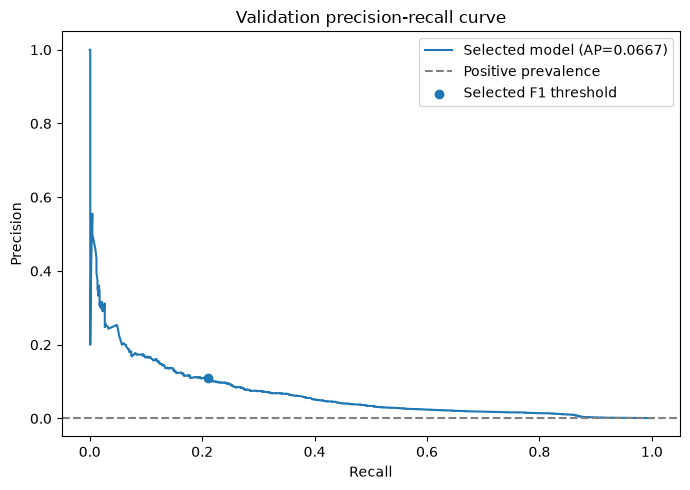

In [11]:
precision, recall, thresholds = precision_recall_curve(y_val, val_scores)
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / np.maximum(precision[:-1] + recall[:-1], 1e-12)
)
best_idx = int(np.argmax(f1_values))
best_threshold = float(thresholds[best_idx])
print("Selected threshold:", best_threshold)
evaluate_validation("Selected model, validation F1 threshold", val_scores, best_threshold)
display(pd.DataFrame(validation_results))

def alert_budget_metrics(y_true, scores, budget=1000):
    labels = np.asarray(y_true)
    k = min(budget, len(labels))
    top = np.argsort(-np.asarray(scores), kind="stable")[:k]
    caught = int(labels[top].sum())
    return {"Alerts": k, "True positives": caught,
            "Precision@budget": caught / k,
            "Recall@budget": caught / max(int(labels.sum()), 1)}

print("Validation alert budget:", alert_budget_metrics(y_val, val_scores))
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"Selected model (AP={average_precision_score(y_val, val_scores):.4f})")
plt.axhline(y_val.mean(), color="gray", linestyle="--", label="Positive prevalence")
plt.scatter(recall[best_idx], precision[best_idx], label="Selected F1 threshold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curve")
plt.legend()
plt.tight_layout()
plt.show()


## Final test evaluation

Run after model and threshold selection. Do not revise parameters or the threshold
based on these results. The final model is not refitted on train + validation,
which keeps the selected validation threshold tied to the same fitted model.


Model: Tuned extra features
Frozen threshold: 0.03698771819472313
Test AP: 0.1654976025946435
Test positive prevalence: 0.0017698905975300282
              precision    recall  f1-score   support

           0     0.9987    0.9986    0.9987   1014084
           1     0.2607    0.2709    0.2657      1798

    accuracy                         0.9974   1015882
   macro avg     0.6297    0.6347    0.6322   1015882
weighted avg     0.9974    0.9974    0.9974   1015882

{'TN': 1012703, 'FP': 1381, 'FN': 1311, 'TP': 487}
Test alert budget: {'Alerts': 1000, 'True positives': 325, 'Precision@budget': 0.325, 'Recall@budget': 0.1807563959955506}


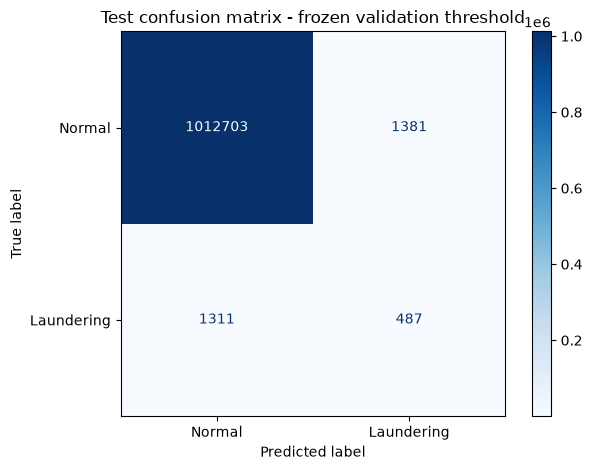

In [12]:
test_scores = model.predict_proba(X_test[selected_columns])[:, 1]
test_pred = (test_scores >= best_threshold).astype("uint8")
print("Model:", selected_name)
print("Frozen threshold:", best_threshold)
print("Test AP:", average_precision_score(y_test, test_scores))
print("Test positive prevalence:", y_test.mean())
print(classification_report(y_test, test_pred, digits=4, zero_division=0))
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
print({"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)})
print("Test alert budget:", alert_budget_metrics(y_test, test_scores))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=[0, 1], display_labels=["Normal", "Laundering"],
    values_format="d", cmap="Blues",
)
plt.title("Test confusion matrix - frozen validation threshold")
plt.tight_layout()
plt.show()


In [13]:
from sklearn.metrics import confusion_matrix

FP_COST = 1
FN_COST = 10

thresholds_to_try = [0.01, 0.02, 0.037, 0.05, 0.1]

cost_results = []

for threshold in thresholds_to_try:

    predictions = (val_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    total_cost = fp * FP_COST + fn * FN_COST

    cost_results.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)

display(cost_df)

,Threshold,False Positives,False Negatives,Total Cost
0,0.010,19635,499,24625
1,0.020,4918,720,12118
2,0.037,1824,856,10384
3,0.050,1003,923,10233
4,0.100,68,1053,10598


In [14]:
penalty_results = []

for fn_cost in [1, 5, 10, 20]:
    temp = cost_df.copy()

    temp["Total Cost"] = (
        temp["False Positives"]
        + fn_cost * temp["False Negatives"]
    )

    best = temp.loc[temp["Total Cost"].idxmin()]

    penalty_results.append({
        "FN Penalty": fn_cost,
        "Best Threshold": best["Threshold"],
        "Minimum Cost": best["Total Cost"]
    })

penalty_df = pd.DataFrame(penalty_results)

display(penalty_df)

,FN Penalty,Best Threshold,Minimum Cost
0,1,0.100,1121.0
1,5,0.100,5333.0
2,10,0.050,10233.0
3,20,0.037,18944.0


In [15]:
comparison = cost_df[
    cost_df["Threshold"].isin([0.100, 0.050, 0.037])
][["Threshold", "False Positives", "False Negatives"]]

display(comparison.sort_values("Threshold", ascending=False))

,Threshold,False Positives,False Negatives
4,0.100,68,1053
3,0.050,1003,923
2,0.037,1824,856


In [16]:
import numpy as np
from sklearn.metrics import confusion_matrix

FP_COST = 1
FN_COST = 10

thresholds = np.linspace(0.001, 0.2, 200)

results = []

for threshold in thresholds:
    predictions = (val_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    cost = fp * FP_COST + fn * FN_COST

    results.append([threshold, fp, fn, cost])

results_df = pd.DataFrame(
    results,
    columns=["Threshold", "FP", "FN", "Cost"]
)

best = results_df.loc[results_df["Cost"].idxmin()]

print("Best Threshold:", best["Threshold"])
print("False Positives:", best["FP"])
print("False Negatives:", best["FN"])
print("Minimum Cost:", best["Cost"])

Best Threshold: 0.061
False Positives: 676.0
False Negatives: 953.0
Minimum Cost: 10206.0


In [17]:
new_threshold = 0.061

predictions = (val_scores >= new_threshold).astype(int)

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.037, 0.061]:
    predictions = (val_scores >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, predictions, zero_division=0), 4))
    print("Recall:   ", round(recall_score(y_val, predictions, zero_division=0), 4))
    print("F1 Score: ", round(f1_score(y_val, predictions, zero_division=0), 4))


Threshold: 0.037
Precision: 0.1102
Recall:    0.2089
F1 Score:  0.1443

Threshold: 0.061
Precision: 0.1602
Recall:    0.1192
F1 Score:  0.1367


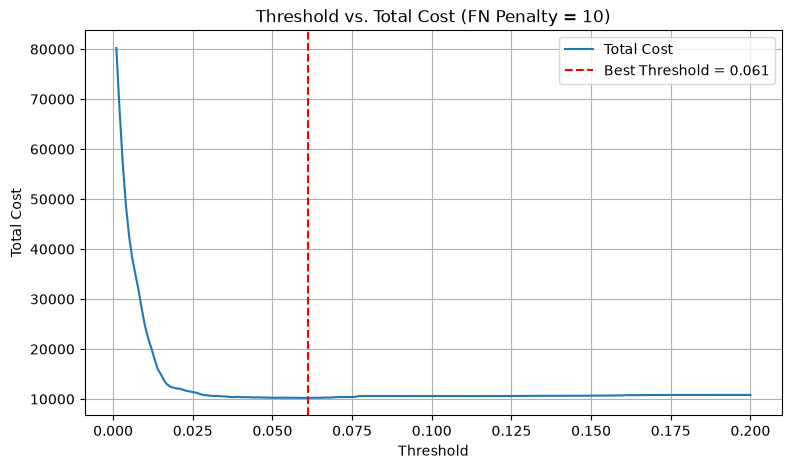

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Threshold"],
    results_df["Cost"],
    label="Total Cost"
)

plt.axvline(
    x=0.061,
    color="red",
    linestyle="--",
    label="Best Threshold = 0.061"
)

plt.xlabel("Threshold")
plt.ylabel("Total Cost")
plt.title("Threshold vs. Total Cost (FN Penalty = 10)")

plt.legend()
plt.grid(True)
plt.show()

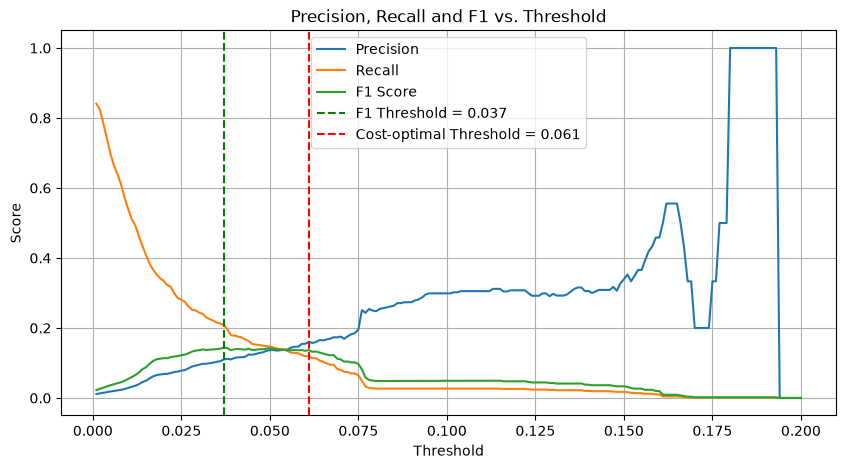

,Method,Threshold,Precision,Recall,F1 Score
0,F1-based,0.037,0.1102,0.2089,0.1443
1,Cost-based,0.061,0.1602,0.1192,0.1367


In [20]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Thresholds to compare
f1_threshold = 0.037
cost_threshold = 0.061

precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:
    predictions = (val_scores >= threshold).astype(int)

    precision_values.append(
        precision_score(y_val, predictions, zero_division=0)
    )
    recall_values.append(
        recall_score(y_val, predictions, zero_division=0)
    )
    f1_values.append(
        f1_score(y_val, predictions, zero_division=0)
    )

# Plot
plt.figure(figsize=(10, 5))

plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.plot(thresholds, f1_values, label="F1 Score")

plt.axvline(
    f1_threshold,
    color="green",
    linestyle="--",
    label="F1 Threshold = 0.037"
)

plt.axvline(
    cost_threshold,
    color="red",
    linestyle="--",
    label="Cost-optimal Threshold = 0.061"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs. Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Comparison table
comparison_results = []

for name, threshold in [
    ("F1-based", f1_threshold),
    ("Cost-based", cost_threshold)
]:
    predictions = (val_scores >= threshold).astype(int)

    comparison_results.append({
        "Method": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


In [21]:
import pandas as pd

class_distribution = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Total Transactions": [
        len(y_train),
        len(y_val),
        len(y_test)
    ],
    "Laundering Transactions": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ]
})

class_distribution["Laundering %"] = (
    class_distribution["Laundering Transactions"]
    / class_distribution["Total Transactions"] * 100
)

display(class_distribution)

,Dataset,Total Transactions,Laundering Transactions,Laundering %
0,Train,3046861,2297,0.075389
1,Validation,1015602,1082,0.106538
2,Test,1015882,1798,0.176989


In [22]:
# Separate normal and laundering transactions
normal_idx = y_train[y_train == 0].index
laundering_idx = y_train[y_train == 1].index

print("Normal:", len(normal_idx))
print("Laundering:", len(laundering_idx))

Normal: 3044564
Laundering: 2297


In [24]:
# Select 20 normal transactions for each laundering transaction
sampled_normal_idx = normal_idx.to_series().sample(
    n=len(laundering_idx) * 20,
    random_state=42
).values

# Combine selected normal and all laundering transactions
sampled_idx = list(sampled_normal_idx) + list(laundering_idx)

# Create sampled training dataset
X_train_sampled = X_train.loc[sampled_idx]
y_train_sampled = y_train.loc[sampled_idx]

print("Original training size:", len(y_train))
print("Sampled training size:", len(y_train_sampled))
print(y_train_sampled.value_counts())

Original training size: 3046861
Sampled training size: 48237
Is Laundering
0    45940
1     2297
Name: count, dtype: int64


In [26]:
from sklearn.base import clone

# Copy original model settings
model_sampled = clone(model)

# Train with undersampled data and validation set
model_sampled.fit(
    X_train_sampled,
    y_train_sampled,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Undersampled XGBoost training completed!")

Undersampled XGBoost training completed!


In [29]:
from sklearn.metrics import average_precision_score

original_ap = average_precision_score(y_val, original_scores)
sampled_ap = average_precision_score(y_val, sampled_scores)

print("Original XGBoost AP:", round(original_ap, 4))
print("Undersampled XGBoost AP:", round(sampled_ap, 4))

Original XGBoost AP: 0.0667
Undersampled XGBoost AP: 0.0637


In [30]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall for different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, sampled_scores
)

# Calculate F1 scores
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the highest F1 score
best_idx = np.argmax(f1_scores)
best_threshold_sampled = thresholds[best_idx]

print("Best Threshold:", round(best_threshold_sampled, 4))
print("Precision:", round(precision[best_idx], 4))
print("Recall:", round(recall[best_idx], 4))
print("F1 Score:", round(f1_scores[best_idx], 4))

Best Threshold: 0.7067
Precision: 0.1175
Recall: 0.1987
F1 Score: 0.1477


In [31]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Predictions using each model's threshold
original_pred = (original_scores >= 0.037).astype(int)
sampled_pred = (sampled_scores >= best_threshold_sampled).astype(int)

# Calculate confusion matrices
tn1, fp1, fn1, tp1 = confusion_matrix(y_val, original_pred).ravel()
tn2, fp2, fn2, tp2 = confusion_matrix(y_val, sampled_pred).ravel()

comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Undersampled XGBoost"],
    "TP": [tp1, tp2],
    "FP": [fp1, fp2],
    "FN": [fn1, fn2],
    "TN": [tn1, tn2]
})

display(comparison)

,Model,TP,FP,FN,TN
0,Original XGBoost,226,1824,856,1012696
1,Undersampled XGBoost,215,1615,867,1012905


In [32]:
FP_COST = 1
FN_COST = 10

original_cost = fp1 * FP_COST + fn1 * FN_COST
sampled_cost = fp2 * FP_COST + fn2 * FN_COST

print("Original XGBoost Cost:", original_cost)
print("Undersampled XGBoost Cost:", sampled_cost)

Original XGBoost Cost: 10384
Undersampled XGBoost Cost: 10285


In [33]:
import numpy as np

threshold_grid = np.linspace(0.001, 0.999, 999)

def find_best_cost_threshold(scores, y_true):
    costs = []

    for t in threshold_grid:
        predictions = (scores >= t).astype(int)

        fp = ((predictions == 1) & (y_true == 0)).sum()
        fn = ((predictions == 0) & (y_true == 1)).sum()

        costs.append(fp + 10 * fn)

    best_idx = np.argmin(costs)

    return threshold_grid[best_idx], costs[best_idx]

original_t, original_cost = find_best_cost_threshold(
    original_scores, y_val
)

sampled_t, sampled_cost = find_best_cost_threshold(
    sampled_scores, y_val
)

print("Original XGBoost:")
print("Best threshold:", round(original_t, 4))
print("Minimum cost:", original_cost)

print("\nUndersampled XGBoost:")
print("Best threshold:", round(sampled_t, 4))
print("Minimum cost:", sampled_cost)

Original XGBoost:
Best threshold: 0.061
Minimum cost: 10206

Undersampled XGBoost:
Best threshold: 0.746
Minimum cost: 10225


In [28]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_val, sampled_pred))

print("\nClassification Report:")
print(classification_report(y_val, sampled_pred, digits=4))

Confusion Matrix:
[[926089  88431]
 [   158    924]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9998    0.9128    0.9544   1014520
           1     0.0103    0.8540    0.0204      1082

    accuracy                         0.9128   1015602
   macro avg     0.5051    0.8834    0.4874   1015602
weighted avg     0.9988    0.9128    0.9534   1015602



In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Predictions on the same validation dataset
original_scores = model.predict_proba(X_val)[:, 1]
sampled_scores = model_sampled.predict_proba(X_val)[:, 1]

# Use the same threshold for a first comparison
threshold = 0.037

original_pred = (original_scores >= threshold).astype(int)
sampled_pred = (sampled_scores >= threshold).astype(int)

results = pd.DataFrame({
    "Model": ["Original XGBoost", "Undersampled XGBoost"],
    "Precision": [
        precision_score(y_val, original_pred, zero_division=0),
        precision_score(y_val, sampled_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_val, original_pred, zero_division=0),
        recall_score(y_val, sampled_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_val, original_pred, zero_division=0),
        f1_score(y_val, sampled_pred, zero_division=0)
    ]
})

display(results)

,Model,Precision,Recall,F1 Score
0,Original XGBoost,0.110244,0.208872,0.144317
1,Undersampled XGBoost,0.010341,0.853974,0.020434
